# Notebook 04: Deep Sequential Time-Series Forecasting (PyTorch LSTM)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fahadrahman444/scientific-research-and-methodologies/blob/main/colab_notebooks/04_Deep_Learning_TimeSeries_Forecasting_Colab.ipynb)

**Research Topic:** A Data-Driven Analysis of 15-Year Weather Variability and Its Impact on Agricultural Crop Yield in Bangladesh  
**Methodological Framework:** Two-Tier Quantitative Design (Option A)  
**Hardware Target:** Google Colab GPU (T4 / V100)  

---
## 1. Deep Recurrent Neural Network Pipeline
Constructs a multi-step sequential LSTM neural network in PyTorch to project crop yield trajectories based on historical rolling weather windows.


In [3]:
# Step 1: Device Verification
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device in use: {device}')
if torch.cuda.is_available():
    print(f'GPU Device: {torch.cuda.get_device_name(0)}')


Device in use: cuda
GPU Device: Tesla T4


In [4]:
# Step 2: Data Ingestion & Sequence Creation
BASE_RAW = 'https://raw.githubusercontent.com/fahadrahman444/scientific-research-and-methodologies/main'
INTEGRATED_LOCAL = '../data/processed/bangladesh_faostat_weather_integrated_15yr.csv'
INTEGRATED_URL = f'{BASE_RAW}/data/processed/bangladesh_faostat_weather_integrated_15yr.csv'

df_nat = pd.read_csv(INTEGRATED_LOCAL) if os.path.exists(INTEGRATED_LOCAL) else pd.read_csv(INTEGRATED_URL)
features = ['tmax', 'tmin', 'rain', 'spi', 'heat_days', 'humidity', 'yield_kg_ha']
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df_nat[features])

def create_sequences(data, seq_len=3):
    xs, ys = [], []
    for i in range(len(data) - seq_len):
        xs.append(data[i:(i + seq_len), :-1])
        ys.append(data[i + seq_len, -1])
    return np.array(xs), np.array(ys)

X_seq, y_seq = create_sequences(scaled, seq_len=3)
print(f'Generated {len(X_seq)} temporal sequences of shape {X_seq.shape}.')

Generated 13 temporal sequences of shape (13, 3, 6).


In [5]:
# Step 3: PyTorch LSTM Architecture
class YieldLSTM(nn.Module):
    def __init__(self, in_dim, hidden_dim=32, num_layers=2):
        super(YieldLSTM, self).__init__()
        self.lstm = nn.LSTM(in_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=0.1)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze()

model = YieldLSTM(in_dim=X_seq.shape[2]).to(device)
print(model)


YieldLSTM(
  (lstm): LSTM(6, 32, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


Epoch [30/150] | Loss: 0.05194
Epoch [60/150] | Loss: 0.01715
Epoch [90/150] | Loss: 0.00415
Epoch [120/150] | Loss: 0.00311
Epoch [150/150] | Loss: 0.00228


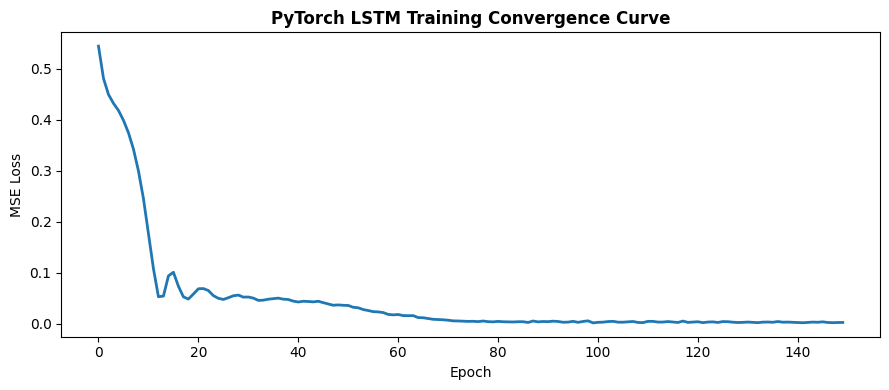

In [6]:
# Step 4: Model Training
X_t = torch.tensor(X_seq, dtype=torch.float32).to(device)
y_t = torch.tensor(y_seq, dtype=torch.float32).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)

epochs = 150
losses = []
for ep in range(epochs):
    model.train()
    optimizer.zero_grad()
    out = model(X_t)
    loss = criterion(out, y_t)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (ep + 1) % 30 == 0:
        print(f'Epoch [{ep+1}/{epochs}] | Loss: {loss.item():.5f}')

plt.figure(figsize=(9, 4))
plt.plot(losses, color='#1f77b4', lw=2)
plt.title('PyTorch LSTM Training Convergence Curve', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.tight_layout()
plt.show()
